## Fitting a generalized Pareto distribution to the exceedance curve

Exceedance frequency curves computed from a probabilistic event set only cover return periods up to the length of the simulated period, and simple extrapolation beyond that can be unreliable. In this code snippet, we fit a generalized Pareto distribution (GPD) to the tail of an exceedance curve, following the peaks-over-threshold approach from extreme value theory, and use it to extrapolate to large return periods. We apply this to impact frequency curves for tropical cyclones in Haiti and river floods in Italy, and to the local flood intensities to obtain return period flood maps.

For any questions regarding the code snippet, please reach out to [vgebhart@ethz.ch](mailto:vgebhart@ethz.ch).

In [1]:
# import packages
import logging
import numpy as np
from scipy import interpolate
from scipy.optimize import minimize
from scipy.stats import genextreme, genpareto

from climada.engine.impact import ImpactFreqCurve

LOGGER = logging.getLogger(__name__)

We first define the helper functions for the fit. The GPD describes the exceedance frequency of values above a threshold, which we set as a percentile of the data. Its shape and scale parameters are fitted by minimizing the squared error between the empirical and modelled exceedance frequencies in log space.

In [2]:
def _gpd_distribution(values, xi, beta, lambda_u, threshold):
    """
    Survival function (1-CDF) using a generalized Pareto distribution for the conditional
    distribution of the tail and a probability of threhsold exceedance (lambda_u).
    See https://en.wikipedia.org/wiki/Generalized_Pareto_distribution
    """
    values = np.asarray(values)
    return lambda_u * (1 + xi * (values - threshold) / beta) ** (-1 / xi)


def _gpd_inverse_distribution(lambdas, xi, beta, lambda_u, threshold):
    """
    Inverse survival function (1-CDF) using a generalized Pareto distribution for the conditional
    distribution of the tail and a probability of threhsold exceedance (lambda_u).
    See https://en.wikipedia.org/wiki/Generalized_Pareto_distribution
    """
    lambdas = np.asarray(lambdas)
    return threshold + (beta / xi) * ((lambdas / lambda_u) ** (-xi) - 1)


def fit_tail_GPD(
    test_frequency=None,
    test_values=None,
    frequency=None,
    values=None,
    value_threshold=0,
    threshold_percentile=90,
    min_sample_size=30,
):
    """
    Fit a generalized Pareto distribution (GPD) to the tail of the  exceedance data
    and extrapolate to test points.

    Extreme value theory provides one principal solution for fitting exceedance values
    using a peaks-over-threshold approach leading to the GPD, see e.g.
    https://en.wikipedia.org/wiki/Generalized_Pareto_distribution and
    (Coles, 2001, Chapter 4, https://doi.org/10.1007/978-1-4471-3675-0).
    The selection of the threshold is a crucial choice because lower thresholds result in
    more data points to fit, while higher thresholds ensure that data points actually
    correspond to extreme values.

    Parameters
    ----------
    test_frequency : array_like, optional
        Exceedance frequencies for which to compute values. If given, test_values must be None.
    test_values : array_like, optional
        Values for which to compute exceedance frequencies. If given, test_frequency must be None.
    frequency : array_like
        Frequencies of the observed values.
    values : array_like
        Observed values.
    value_threshold : float, optional
        Value threshold to filter values before the threshold percentile is calculated.
        Defaults to 0, filtering out all values less or equal to zero.
    threshold_percentile : float, optional
        Percentile for the tail threshold. Defaults to 90.
    min_sample_size : int, optional
        Minimum number of points above the threshold. Defaults to 30.

    Returns
    -------
    tuple
        (test_frequency, values) if test_frequency is given, else (exceedance_frequencies, test_values)
    """

    # Validate inputs
    if (test_frequency is not None and test_values is not None) or (
        test_frequency is None and test_values is None
    ):
        raise ValueError("Provide exactly one of test_frequency or test_values")

    # Filter by value_threshold before computing threshold with percentile
    mask_filter = values > value_threshold
    frequency = frequency[mask_filter]
    values = values[mask_filter]

    # compute percentile threshold and select tail
    threshold = np.percentile(values, threshold_percentile)
    mask = values > threshold
    values_tail = values[mask]
    frequency_tail = frequency[mask]
    if sum(mask) < min_sample_size:
        raise ValueError(
            f"Not enough data points above the threshold for fitting the GPD. You can try to "
            f"choose a smaller threshold_percentile={threshold_percentile} or a smaller "
            f"min_sample_size={min_sample_size}."
        )

    # Sort values and frequencies
    sorted_idxs = np.argsort(values_tail)
    values_tail = np.squeeze(values_tail[sorted_idxs])
    frequency_tail = frequency_tail[sorted_idxs]
    ex_freq = np.cumsum(frequency_tail[::-1])[::-1]
    lambda_u = ex_freq[0]  # estimated frequency for exceeding the threshold

    def exceedance_negerror(params):
        """function to be optimized: summed squared of log errors"""
        _, beta = params
        if beta <= 0:
            return np.inf
        model = _gpd_distribution(values_tail, *params, lambda_u, threshold)
        return np.sum((np.log(ex_freq) - np.log(model)) ** 2)

    res = minimize(
        exceedance_negerror,
        [0.1, np.std(values_tail - threshold)],
        bounds=[(-1, None), (1e-6, None)],
    )
    xi_hat, beta_hat = res.x
    fit_result = {"xi": xi_hat, "beta": beta_hat}
    LOGGER.info(
        "Fitted GPD parameters using %.3g points: xi=%.3g, beta=%.3g.",
        sum(mask),
        xi_hat,
        beta_hat,
    )

    # Compute some goodness-of-fit metrics
    # Recompute model on tail with fitted params
    model_tail = _gpd_distribution(values_tail, xi_hat, beta_hat, lambda_u, threshold)
    # Avoid log(0) issues
    eps = 1e-12
    lambda_tail_safe = np.maximum(ex_freq, eps)
    model_tail_safe = np.maximum(model_tail, eps)
    # Root mean-squared error (log-survival space)
    residuals = np.log(lambda_tail_safe) - np.log(model_tail_safe)
    rmse_log = np.sqrt(np.mean(residuals**2))

    # Kolmogorov–Smirnov distance on normalized survival function
    empirical_prob = lambda_tail_safe / lambda_u
    model_prob = model_tail_safe / lambda_u
    ks_distance = np.max(np.abs(empirical_prob - model_prob))

    fit_result.update({"rmse_log": rmse_log, "ks_distance": ks_distance})
    LOGGER.info(
        "GOF metrics: RMSE_log=%.3g, KS=%.3g",
        rmse_log,
        ks_distance,
    )

    if test_values is not None:
        mask_tail = test_values > threshold
        lambda_dist = _gpd_distribution(
            test_values, xi_hat, beta_hat, lambda_u, threshold
        )
        lambda_dist[~mask_tail] = np.nan
        return (lambda_dist, test_values, fit_result)
    else:
        vals = _gpd_inverse_distribution(
            test_frequency, xi_hat, beta_hat, lambda_u, threshold
        )
        mask_tail = vals > threshold
        vals[~mask_tail] = np.nan
        return (test_frequency, vals, fit_result)

Next, we define a function that takes an `ImpactFreqCurve`, fits a GPD to the tail of its impacts and returns a new `ImpactFreqCurve` evaluated at the given return periods.

In [3]:
def fit_GPD_to_ImpFreqCurve(
    freq_curve,
    return_periods,
    min_impact=0,
    threshold_percentile=90,
    min_sample_size=20,
):
    """
        Fit a generalized Pareto distribution (GPD) to the tail of an ImpactFreqCurve.
    
        Extreme value theory provides one principal solution for fitting exceedance values
        using a peaks-over-threshold approach leading to the GPD, see e.g.
        https://en.wikipedia.org/wiki/Generalized_Pareto_distribution and
        (Coles, 2001, Chapter 4, https://doi.org/10.1007/978-1-4471-3675-0).
        The selection of the threshold is a crucial choice because lower thresholds result in
        more data points to fit, while higher thresholds ensure that data points actually
        correspond to extreme values.
    
        Parameters
        ----------
        freq_curve : climada.engine.impact.ImpactFreqCurve
            Exceedance frequency curve to be fitted.
        return_periods : Iterable[float]
            return periods for which to evaluate the impact frequency curve
        min_impact : float, optional
            Minimum threshold to filter the impact. Defaults to 0.
        threshold_percentile : float, optional
            Defines percentile to set threshold in GPD peak-over-threshold,
            after first filtering out all impacts below min_impact. Defaults to 90.
        min_sample_size : int, optinal
            Has only effect if method is "fit_GPD". Minimal sample size to require for fitting
            GPD to the tail. Defaults to 20.
    
        Returns
        -------
        climada.engine.impact.ImpactFreqCurve
            Fitted Exceedance frequency curve to be fitted.
        """

    exceedance_frequency = 1 / np.array(return_periods)
    # sort return periods of ImpactFreqCurve
    sorted_idxs = np.argsort(freq_curve.return_per)
    impacts = np.squeeze(np.array(freq_curve.impact)[sorted_idxs])
    rps = np.asarray(freq_curve.return_per)[sorted_idxs]
    frequency = np.diff(1 / np.array(rps)[::-1], prepend=0)[::-1]


    _, impact_interpolated, _ = fit_tail_GPD(
            exceedance_frequency,
            None,
            frequency,
            impacts,
            value_threshold=min_impact,
            min_sample_size=min_sample_size,
            threshold_percentile=threshold_percentile,
        )
    
    return ImpactFreqCurve(
            return_per=return_periods,
            impact=impact_interpolated,
            unit=freq_curve.unit,
            frequency_unit=freq_curve.frequency_unit,
            label=freq_curve.label,
        )

### Example 1: Tropical cyclone impacts in Haiti

We compute the impacts of a probabilistic tropical cyclone event set on the LitPop exposure of Haiti, using the Emanuel impact function.

In [4]:
from climada.entity import ImpactFunc, ImpactFuncSet, ImpfTropCyclone
from climada.util.api_client import Client
from climada.engine import ImpactCalc
import matplotlib.pyplot as plt
import numpy as np

client = Client()

impf_set = ImpactFuncSet([ImpfTropCyclone.from_emanuel_usa()])

exp = client.get_litpop(country="Haiti")

haz = client.get_hazard(
    "tropical_cyclone",
    properties={
        "country_name": "Haiti",
        "climate_scenario": "historical",
        "nb_synth_tracks": "10",
    },
)

impact = ImpactCalc(exp, impf_set, haz).impact()

The standard impact frequency curve contains one point per event and is therefore limited to the return periods of the event set.

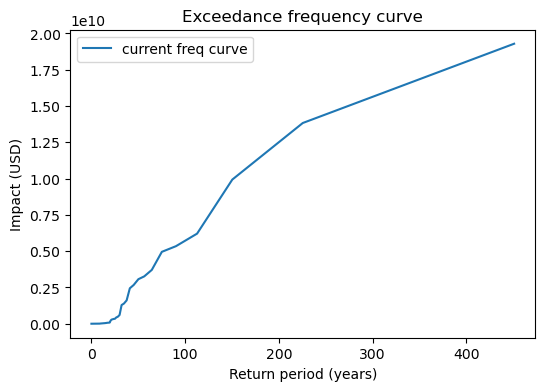

In [5]:
freq_curve = impact.calc_freq_curve()
_, ax = plt.subplots(1, 1, figsize=(6, 4))
freq_curve.plot(axis=ax, label="current freq curve")
ax.legend();

We now compare the built-in log-log extrapolation of `ImpactFreqCurve.interpolate` with GPD fits using different threshold percentiles. A higher percentile uses fewer but more extreme points for the fit.

/Users/vgebhart/gitprojects/climada_repo/climada_python/climada/engine/impact.py:2404: RuntimeWarning: divide by zero encountered in divide
  exceedance_frequency = 1 / np.array(return_periods)
/var/folders/04/tbpkdd855mg6mjr2mj6h1csh0000gp/T/ipykernel_85329/2503294668.py:40: RuntimeWarning: divide by zero encountered in divide
  exceedance_frequency = 1 / np.array(return_periods)


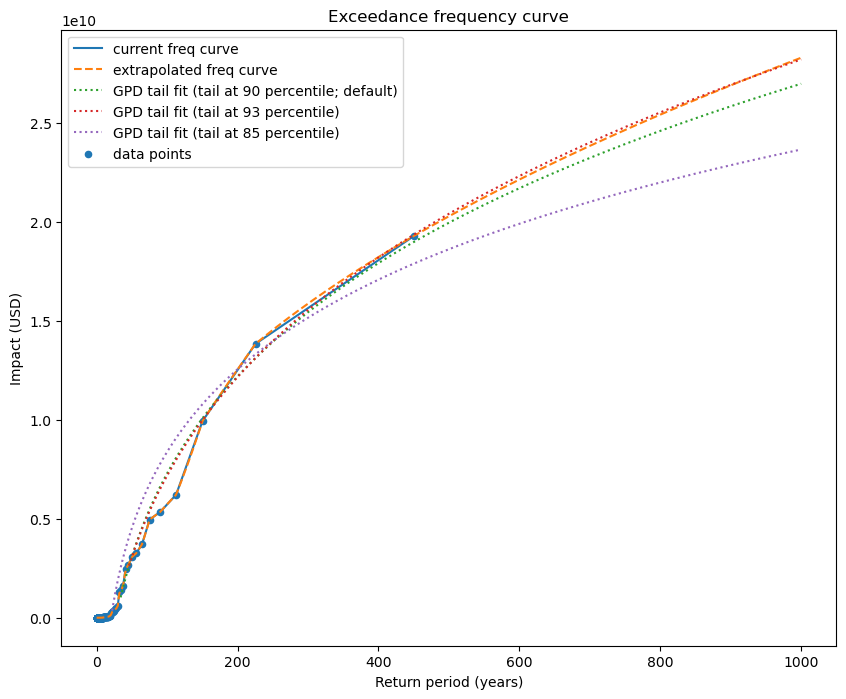

In [6]:
return_periods = np.linspace(0, 1000, 500)
freq_curve_extrapolated = freq_curve.interpolate(
    return_periods=return_periods, method="extrapolate"
)
freq_curve_fit_GPD = fit_GPD_to_ImpFreqCurve(
    freq_curve, return_periods, min_sample_size=10,
)
freq_curve_fit_GPD_93 = fit_GPD_to_ImpFreqCurve(
    freq_curve, return_periods, min_sample_size=10, threshold_percentile=93,
)
freq_curve_fit_GPD_85 = fit_GPD_to_ImpFreqCurve(
    freq_curve, return_periods, min_sample_size=10, threshold_percentile=85,
)


fig, ax = plt.subplots(1, 1, figsize=(10, 8))
freq_curve.plot(axis=ax, label="current freq curve")
freq_curve_extrapolated.plot(axis=ax, label="extrapolated freq curve", linestyle="--")
freq_curve_fit_GPD.plot(
    axis=ax, label="GPD tail fit (tail at 90 percentile; default)", linestyle=":"
)
freq_curve_fit_GPD_93.plot(
    axis=ax, label="GPD tail fit (tail at 93 percentile)", linestyle=":"
)
freq_curve_fit_GPD_85.plot(
    axis=ax, label="GPD tail fit (tail at 85 percentile)", linestyle=":"
)
ax.scatter(freq_curve.return_per, freq_curve.impact, label="data points", s=20)
ax.legend();

### Example 2: River floods in Italy

We repeat the analysis for river flood impacts in Italy, using a flood hazard and a simple flood impact function.

In [7]:
client = Client()

exp_ita = client.get_litpop(country="Italy")

rf = client.get_hazard(
    "river_flood",
    properties={
        "country_name": "Italy",
        "climate_scenario": "historical",
    },
)

impf = ImpactFunc()
# based on iaimip test runs in MATLAB, ca 2017, with impact function 20160929, a dummy FL damage function, a copy of TS
impf.intensity = np.array(
    [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8, 10, 16]
)
impf.mdd = np.array([0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.65, 0.675, 0.7, 0.71, 0.72, 0.725, 0.725, 0.725, 0.725])
impf.paa = np.array([0, 0.39346934, 0.632120559, 0.77686984, 0.864664717, 0.917915001, 0.950212932, 0.969802617, 0.981684361, 0.988891003, 0.993262053, 0.995913229, 0.997521248, 0.998496561, 0.999088118, 0.999446916, 0.999664537, 0.9999546, 0.999999887])
impf.haz_type = "RF"
impf.intensity_unit = "m"
impf.id = 1
impf_set_rf = ImpactFuncSet([impf])

impact_ita = ImpactCalc(exp_ita, impf_set_rf, rf).impact()

2026-10-29 18:52:33,573 - climada.util.coordinates - WARNING - Distance to closest centroid is greater than 0.083333 degree for 3 coordinates.


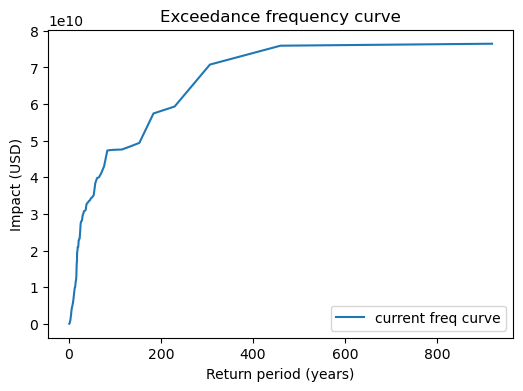

In [8]:
freq_curve_ita = impact_ita.calc_freq_curve()
_, ax = plt.subplots(1, 1, figsize=(6, 4))
freq_curve_ita.plot(axis=ax, label="current freq curve")
ax.legend();

As before, we compare the log-log extrapolation with GPD fits for different threshold percentiles.

/Users/vgebhart/gitprojects/climada_repo/climada_python/climada/engine/impact.py:2404: RuntimeWarning: divide by zero encountered in divide
  exceedance_frequency = 1 / np.array(return_periods)
/var/folders/04/tbpkdd855mg6mjr2mj6h1csh0000gp/T/ipykernel_85329/2503294668.py:40: RuntimeWarning: divide by zero encountered in divide
  exceedance_frequency = 1 / np.array(return_periods)
/var/folders/04/tbpkdd855mg6mjr2mj6h1csh0000gp/T/ipykernel_85329/4003269511.py:8: RuntimeWarning: invalid value encountered in power
  return lambda_u * (1 + xi * (values - threshold) / beta) ** (-1 / xi)
/var/folders/04/tbpkdd855mg6mjr2mj6h1csh0000gp/T/ipykernel_85329/4003269511.py:102: RuntimeWarning: invalid value encountered in log
  return np.sum((np.log(ex_freq) - np.log(model)) ** 2)


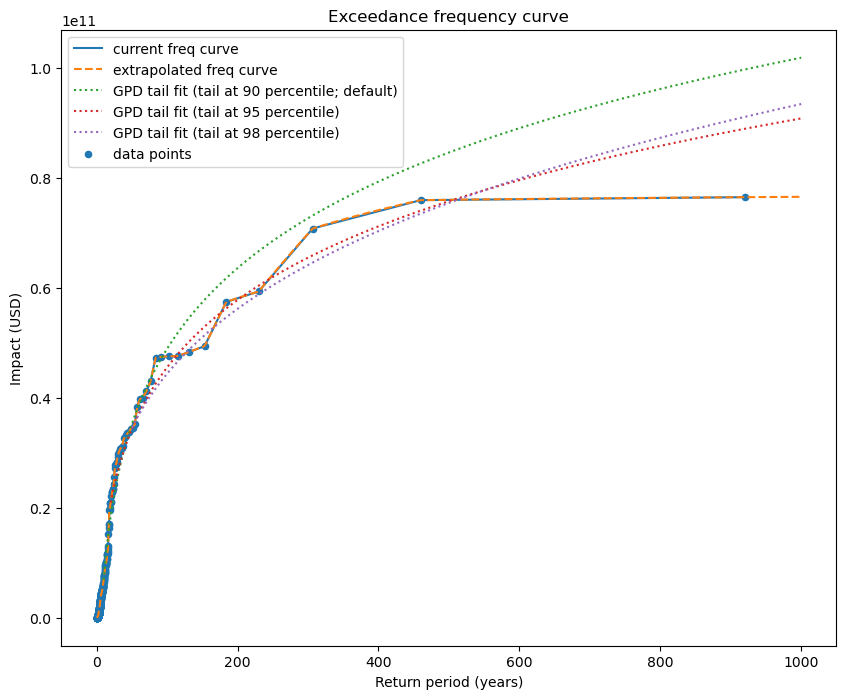

In [9]:
return_periods_ita = np.linspace(0, 1000, 500)
freq_curve_extrapolated_ita = freq_curve_ita.interpolate(
    return_periods=return_periods_ita, method="extrapolate"
)
freq_curve_fit_GPD_ita = fit_GPD_to_ImpFreqCurve(
    freq_curve_ita, return_periods_ita, min_sample_size=10
)
freq_curve_fit_GPD_ita_95 = fit_GPD_to_ImpFreqCurve(
    freq_curve_ita, return_periods_ita, min_sample_size=10, threshold_percentile=95,
)
freq_curve_fit_GPD_ita_98 = fit_GPD_to_ImpFreqCurve(
        freq_curve_ita, return_periods_ita, min_sample_size=10, threshold_percentile=98,
)


fig, ax = plt.subplots(1, 1, figsize=(10, 8))
freq_curve_ita.plot(axis=ax, label="current freq curve")
freq_curve_extrapolated_ita.plot(
    axis=ax, label="extrapolated freq curve", linestyle="--"
)
freq_curve_fit_GPD_ita.plot(
    axis=ax, label="GPD tail fit (tail at 90 percentile; default)", linestyle=":"
)
freq_curve_fit_GPD_ita_95.plot(
    axis=ax, label="GPD tail fit (tail at 95 percentile)", linestyle=":"
)
freq_curve_fit_GPD_ita_98.plot(
    axis=ax, label="GPD tail fit (tail at 98 percentile)", linestyle=":"
)
ax.scatter(freq_curve_ita.return_per, freq_curve_ita.impact, label="data points", s=20)
ax.legend();

### Hazard maps from a GPD fit of the local intensities

The same tail fitting can be applied to the hazard itself: at each centroid, we fit a GPD to the
exceedance curve of the local flood depths of the probabilistic event set and evaluate it at the
desired return periods. This yields return period flood maps similar to
`Hazard.local_exceedance_intensity`, but with an extreme value-based extrapolation beyond the
observed return periods.

Note that, for floods, most centroids are only flooded by a small number of events. Since a GPD
fit is only meaningful with enough data in the tail, centroids where fewer than `min_sample_size`
intensities lie above the tail threshold are assigned NaN.

In [10]:
import geopandas as gpd
import climada.util.dates_times as u_dt
from climada.util.plot import plot_from_gdf


def fit_GPD_to_hazard(
    hazard,
    return_periods=(25, 50, 100, 250),
    min_intensity=0,
    threshold_percentile=90,
    min_sample_size=20,
):
    """
    Fit a generalized Pareto distribution (GPD) to the tail of the local intensities of a
    Hazard and compute local exceedance intensities for given return periods.

    Parameters
    ----------
    hazard : climada.hazard.Hazard
        Hazard whose local exceedance intensities are computed.
    return_periods : array_like, optional
        Return periods for which to compute the local exceedance intensities.
        Defaults to (25, 50, 100, 250).
    min_intensity : float, optional
        Minimum threshold to filter the hazard intensity. Defaults to 0.
    threshold_percentile : float, optional
        Defines percentile to set threshold in GPD peak-over-threshold, after first filtering
        out all intensities below min_intensity. Defaults to 90.
    min_sample_size : int, optional
        Minimal sample size to require for fitting the GPD to the tail. Centroids with fewer
        intensities above the threshold are assigned NaN. Defaults to 20.

    Returns
    -------
    gdf : gpd.GeoDataFrame
        GeoDataFrame containing exceedance intensities for given return periods. Each column
        corresponds to a return period, each row corresponds to a centroid.
    label : str
        GeoDataFrame label, for reporting and plotting
    column_label : function
        Column-label-generating function, for reporting and plotting
    """
    return_period_unit = u_dt.convert_frequency_unit_to_time_unit(hazard.frequency_unit)
    test_frequency = 1 / np.asarray(return_periods, dtype=float)
    exceedance_intensity = np.full((hazard.centroids.size, len(test_frequency)), np.nan)

    # only fit centroids with enough intensities above the tail threshold
    intensity = hazard.intensity.tocsc()
    n_above_min = np.asarray((intensity > min_intensity).sum(axis=0)).ravel()
    candidates = np.where(
        n_above_min * (1 - threshold_percentile / 100) >= min_sample_size
    )[0]

    n_fitted = 0
    for i_centroid in candidates:
        try:
            _, exceedance_intensity[i_centroid], _ = fit_tail_GPD(
                test_frequency,
                None,
                hazard.frequency,
                intensity[:, i_centroid].toarray().ravel(),
                value_threshold=min_intensity,
                threshold_percentile=threshold_percentile,
                min_sample_size=min_sample_size,
            )
            n_fitted += 1
        except ValueError:
            continue
    LOGGER.info("Fitted GPD at %d of %d centroids.", n_fitted, hazard.centroids.size)

    # create the output GeoDataFrame
    gdf = gpd.GeoDataFrame(
        geometry=hazard.centroids.gdf["geometry"], crs=hazard.centroids.gdf.crs
    )
    column_names = [f"{rp}" for rp in return_periods]
    gdf[column_names] = exceedance_intensity

    # create label and column_label
    label = f"Intensity ({hazard.units})"

    def column_label(column_names):
        return [f"Return Period: {col} {return_period_unit}" for col in column_names]

    return gdf, label, column_label

The Italian river flood hazard consists of 920 events with a frequency of 1/920 per year each,
and most centroids are flooded only by a few dozen events. We therefore use a lower threshold
percentile (50) than in the impact examples, so that enough centroids have at least
`min_sample_size` intensities in the tail.

In [11]:
return_periods_rf = [100, 250, 500, 1000]

rf_gdf_GPD, rf_label, rf_column_label = fit_GPD_to_hazard(
    rf, return_periods_rf, threshold_percentile=50, min_sample_size=10
)
rf_gdf_interp, _, _ = rf.local_exceedance_intensity(
    return_periods_rf, method="interpolate"
)

print(f"Centroids with GPD fit: {rf_gdf_GPD[str(return_periods_rf[0])].notna().sum()}")
print(f"Centroids with flooding: {(rf.intensity.getnnz(axis=0) > 0).sum()}")

/var/folders/04/tbpkdd855mg6mjr2mj6h1csh0000gp/T/ipykernel_85329/4003269511.py:8: RuntimeWarning: invalid value encountered in power
  return lambda_u * (1 + xi * (values - threshold) / beta) ** (-1 / xi)
/var/folders/04/tbpkdd855mg6mjr2mj6h1csh0000gp/T/ipykernel_85329/4003269511.py:102: RuntimeWarning: invalid value encountered in log
  return np.sum((np.log(ex_freq) - np.log(model)) ** 2)
/var/folders/04/tbpkdd855mg6mjr2mj6h1csh0000gp/T/ipykernel_85329/4003269511.py:102: RuntimeWarning: divide by zero encountered in log
  return np.sum((np.log(ex_freq) - np.log(model)) ** 2)
/Users/vgebhart/miniforge3/envs/climada_dev/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


Centroids with GPD fit: 948
Centroids with flooding: 3992


Exceedance curve at the centroid with the most flood events: observed data, the standard
inter-/extrapolation, and the GPD tail fit.

/Users/vgebhart/miniforge3/envs/climada_dev/lib/python3.11/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/Users/vgebhart/miniforge3/envs/climada_dev/lib/python3.11/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/Users/vgebhart/miniforge3/envs/climada_dev/lib/python3.11/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is us

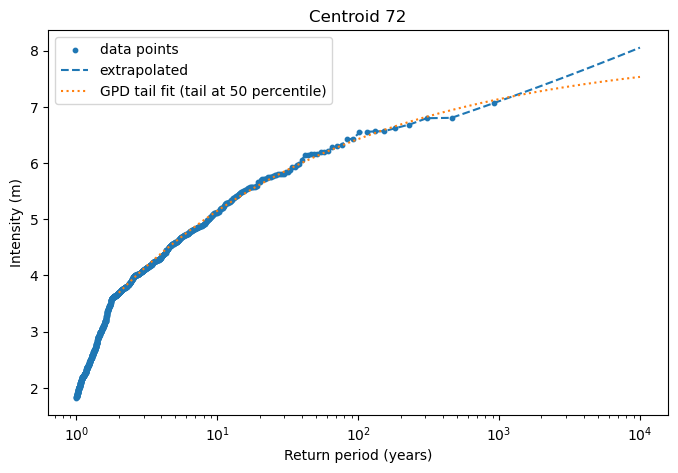

In [12]:
i_centroid = np.argmax(rf.intensity.getnnz(axis=0))
intensity_cen = rf.intensity[:, i_centroid].toarray().ravel()

sorted_idxs = np.argsort(intensity_cen)[::-1]
return_periods_obs = 1 / np.cumsum(rf.frequency[sorted_idxs])
return_periods_test = np.logspace(0, 4, 200)

rf_gdf_extrap_cen, _, _ = rf.local_exceedance_intensity(
    return_periods_test, method="extrapolate"
)
rf_gdf_GPD_cen, _, _ = fit_GPD_to_hazard(
    rf, return_periods_test, threshold_percentile=50, min_sample_size=10
)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.scatter(return_periods_obs, intensity_cen[sorted_idxs], s=10, label="data points")
ax.plot(
    return_periods_test,
    rf_gdf_extrap_cen.iloc[i_centroid, 1:].values,
    linestyle="--",
    label="extrapolated",
)
ax.plot(
    return_periods_test,
    rf_gdf_GPD_cen.iloc[i_centroid, 1:].values,
    linestyle=":",
    label="GPD tail fit (tail at 50 percentile)",
)
ax.set_xscale("log")
ax.set_xlabel("Return period (years)")
ax.set_ylabel(rf_label)
ax.set_title(f"Centroid {i_centroid}")
ax.legend();

Return period flood maps from the GPD fit. Return periods beyond the observed 920 years (here
1000 years) can only be obtained by extrapolation.

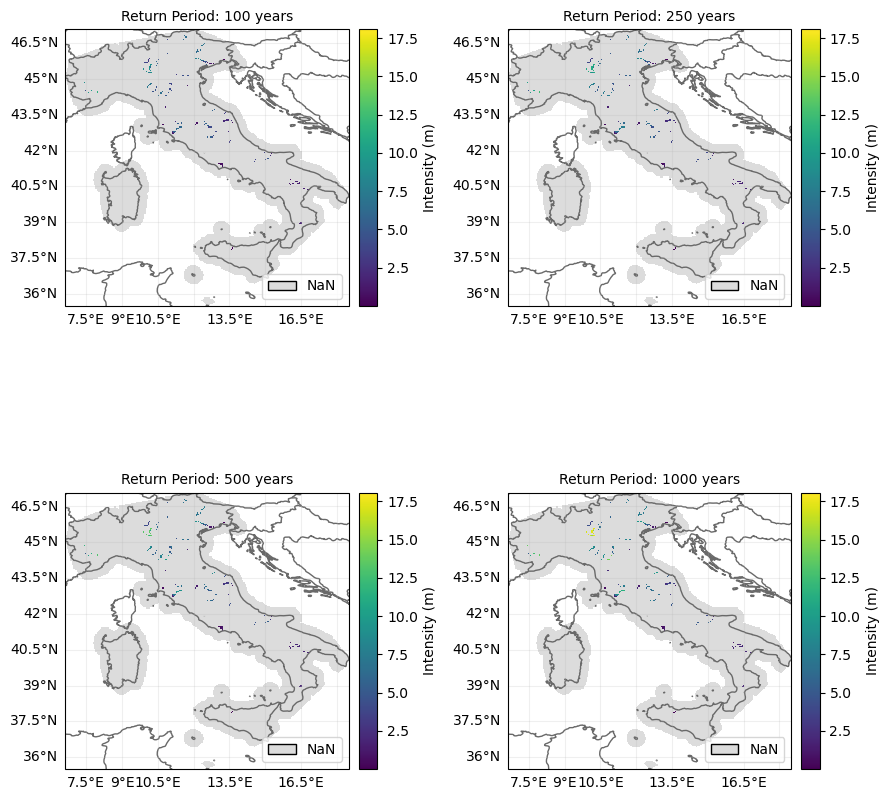

In [13]:
plot_from_gdf(rf_gdf_GPD, colorbar_name=rf_label, title_subplots=rf_column_label);

For comparison, the maps obtained with the standard interpolation, which yields NaN for return
periods outside the observed range at each centroid.

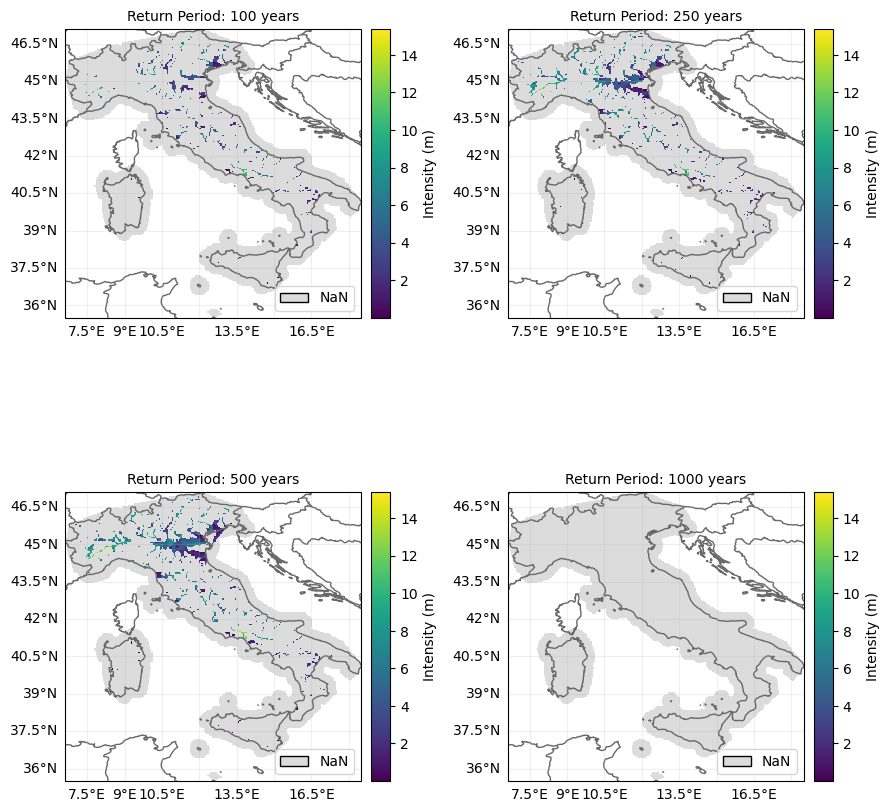

In [14]:
plot_from_gdf(rf_gdf_interp, colorbar_name=rf_label, title_subplots=rf_column_label);

To obtain complete flood maps, one can use the GPD fit where it is available and fall back to the
interpolated values elsewhere.

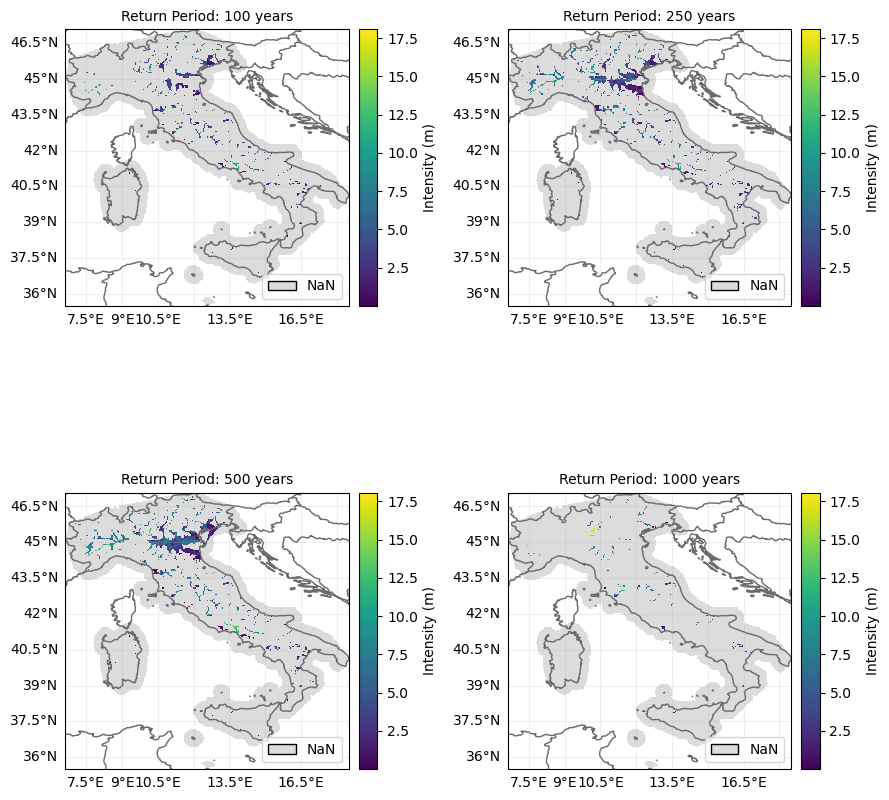

In [15]:
rf_gdf_combined = rf_gdf_GPD.fillna(rf_gdf_interp)
plot_from_gdf(rf_gdf_combined, colorbar_name=rf_label, title_subplots=rf_column_label);

Finally, we show the difference between the GPD-based maps and the maps obtained with the CLIMADA method `Hazard.local_exceedance_intensity` using `method="extrapolate"`, which also yields values for the 1000-year return period. Positive values mean that the GPD fit gives higher flood depths than the log-log extrapolation. Centroids without a GPD fit are shown as NaN, and the color scale is capped to make smaller differences visible.

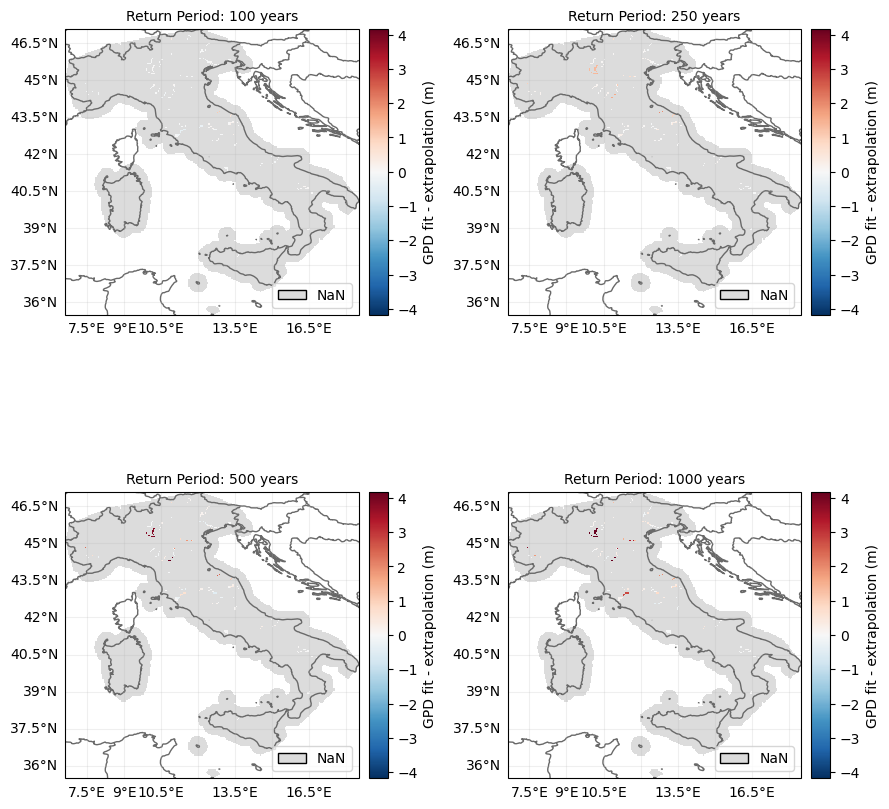

In [16]:
rf_gdf_extrap, _, _ = rf.local_exceedance_intensity(
    return_periods_rf, method="extrapolate"
)

column_names_rf = [f"{rp}" for rp in return_periods_rf]
rf_gdf_diff = rf_gdf_GPD.copy()
rf_gdf_diff[column_names_rf] = (
    rf_gdf_GPD[column_names_rf] - rf_gdf_extrap[column_names_rf]
)

# cap the color scale at the 98th percentile of absolute differences to reduce the effect of outliers
max_abs_diff = np.nanpercentile(np.abs(rf_gdf_diff[column_names_rf].values), 98)
plot_from_gdf(
    rf_gdf_diff,
    colorbar_name=f"GPD fit - extrapolation ({rf.units})",
    title_subplots=rf_column_label,
    cmap="RdBu_r",
    vmin=-max_abs_diff,
    vmax=max_abs_diff,
);

The same differences, zoomed in on a part of the central Po valley in Lombardy, between Bergamo, Brescia and Cremona, where the largest differences occur.

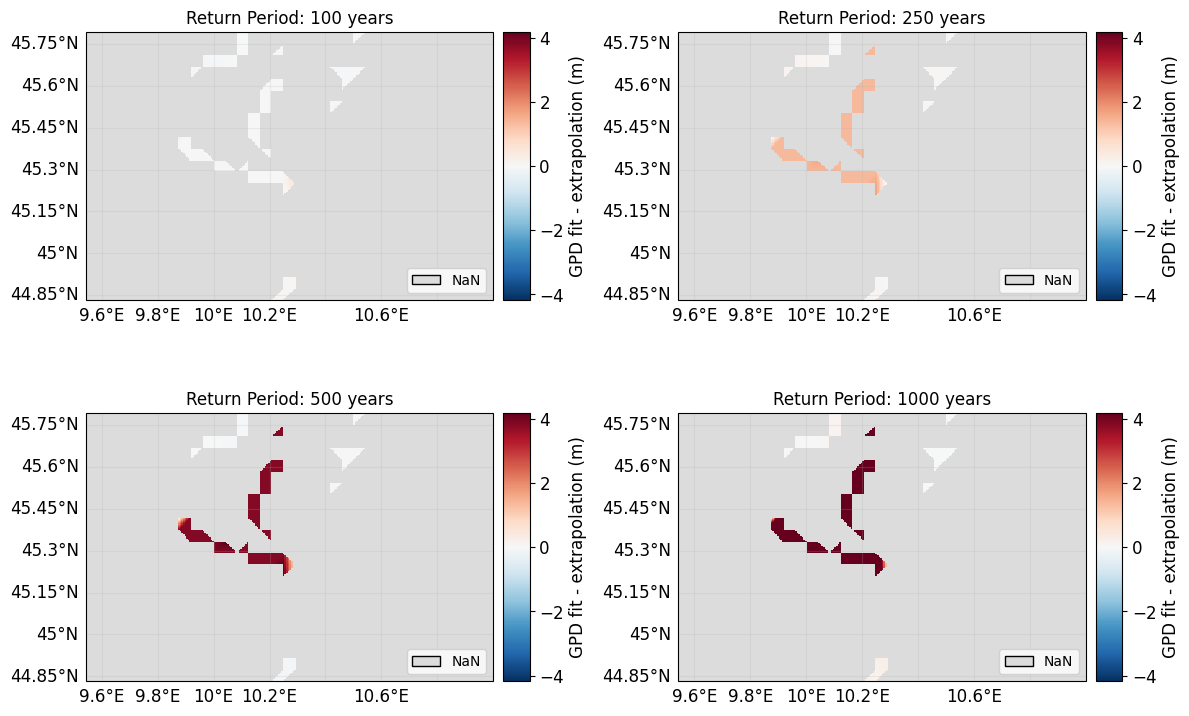

In [17]:
# select centroids in the central Po valley
po_valley = rf_gdf_diff.cx[9.5:11.0, 44.8:45.8]

plot_from_gdf(
    po_valley,
    colorbar_name=f"GPD fit - extrapolation ({rf.units})",
    title_subplots=rf_column_label,
    cmap="RdBu_r",
    vmin=-max_abs_diff,
    vmax=max_abs_diff,
    figsize=(12, 10),
);